In [ ]:
import os
import re
import shutil
import string
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, losses

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
from tensorflow.keras.datasets import imdb

max_words_for_download = 10000
try:
    (x_train_ids, y_train), (x_test_ids, y_test) = imdb.load_data(
        num_words=max_words_for_download,
        index_from=3
    )
    word_index = imdb.get_word_index()
except Exception as e:
    raise RuntimeError(
        "IMDb download failed. In Google Colab, check Runtime > Change runtime type and "
        "make sure internet access is allowed, then rerun this cell. "
        "The Keras IMDb mirror must be reachable for the first download. Original error: " + str(e)
    )

index_to_word = {index + 3: word for word, index in word_index.items()}
index_to_word[0] = ""
index_to_word[1] = "start"
index_to_word[2] = "unknown"

def decode_review(token_ids):
    return " ".join(index_to_word.get(int(token), "unknown") for token in token_ids if int(token) != 0)

train_reviews = np.array([decode_review(review) for review in x_train_ids], dtype=str)
test_reviews = np.array([decode_review(review) for review in x_test_ids], dtype=str)
y_train = np.asarray(y_train, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

print("Training reviews:", len(train_reviews))
print("Test reviews:", len(test_reviews))
print("Example raw review:\n", train_reviews[0][:500])

Training reviews: 25000
Test reviews: 25000
Example raw review:
 start this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert unknown is an amazing actor and now the same being director unknown father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for unknown and woul


In [ ]:
batch_size = 32
seed = 42

# Shuffle the original training examples before taking the validation split.
rng = np.random.default_rng(seed)
indices = rng.permutation(len(train_reviews))
val_size = int(0.2 * len(indices))
val_indices = indices[:val_size]
train_indices = indices[val_size:]

class_names = ["neg", "pos"]

raw_train_ds = tf.data.Dataset.from_tensor_slices(
    (train_reviews[train_indices], y_train[train_indices])
).shuffle(10000, seed=seed).batch(batch_size)

raw_val_ds = tf.data.Dataset.from_tensor_slices(
    (train_reviews[val_indices], y_train[val_indices])
).batch(batch_size)

raw_test_ds = tf.data.Dataset.from_tensor_slices(
    (test_reviews, y_test)
).batch(batch_size)

print("Training examples:", len(train_indices))
print("Validation examples:", len(val_indices))
print("Test examples:", len(test_reviews))
print("Label 0 =", class_names[0], "| Label 1 =", class_names[1])

Training examples: 20000
Validation examples: 5000
Test examples: 25000
Label 0 = neg | Label 1 = pos


In [ ]:
for text_batch, label_batch in raw_train_ds.take(1):
    for i in range(3):
        print("\\nReview:", text_batch.numpy()[i].decode("utf-8")[:500])
        print("Label:", class_names[int(label_batch[i])])

\nReview: start the only way this is a family drama is if parents explain everything wrong with its message br br spoiler they feed a deer for a year and then kill it for eating their food after killing its mother and at first unknown about taking responsibility for their actions they blame bears and deer for unknown by eating while they take no responsibility to use adequate locks and unknown or even learn to shoot instead of twice unknown animals and letting them unknown
Label: neg
\nReview: start after tracking it down for half a year i finally found a copy and it was not disappointing br br not disappointing because i'm one of those die hard unknown fans who need to see all their works and i finally got to see the so called hot film of unknown but i couldn't believe unknown was forced to make a movie as such in his respectable self now i'm sure he unknown that he made this movie nevertheless they found the perfect person for looking embarrassed ill at ease and half depressed most 


In [ ]:
def custom_standardization(input_data):
    lowercase = tf.strings.lower(input_data)
    stripped_html = tf.strings.regex_replace(lowercase, "<br />", " ")
    return tf.strings.regex_replace(
        stripped_html,
        "[%s]" % re.escape(string.punctuation),
        ""
    )

max_tokens = 10000
sequence_length = 250

vectorize_layer = layers.TextVectorization(
    standardize=custom_standardization,
    max_tokens=max_tokens,
    output_mode="int",
    output_sequence_length=sequence_length
)

# Adapt the vocabulary using training text only (not validation/test text).
train_text = raw_train_ds.map(lambda text, label: text)
vectorize_layer.adapt(train_text)

print("Vocabulary size:", len(vectorize_layer.get_vocabulary()))

Vocabulary size: 9908


In [ ]:
for text_batch, label_batch in raw_train_ds.take(1):
    sample_review = text_batch[0]
    sample_label = label_batch[0]

    print("Original review:\\n", sample_review.numpy().decode("utf-8")[:500])
    print("\\nLabel:", class_names[int(sample_label)])
    print("\\nVectorized review (first 30 token IDs):")
    print(vectorize_layer(tf.expand_dims(sample_review, -1)).numpy()[0][:30])

vocabulary = vectorize_layer.get_vocabulary()
print("\\nExample vocabulary entries:")
for token_id in [2, 3, 4, 5]:
    if token_id < len(vocabulary):
        print(token_id, "->", vocabulary[token_id])

Original review:\n start sudden impact is the best of the five dirty harry movies they don't come any unknown and unknown than this as harry unknown through a series of violent unknown with the bad guys getting their just unknown which is just the way i like it great story too and unknown directed by clint himself excellent entertainment
\nLabel: pos
\nVectorized review (first 30 token IDs):
[  30 2049 1539    8    3  116    6    3  691 1643 1300   95   37   92
  214  102    2    4    2   74   13   16 1300    2  144    5  207    6
 1095    2]
\nExample vocabulary entries:
2 -> unknown
3 -> the
4 -> and
5 -> a


In [ ]:
def vectorize_text(text, label):
    text = tf.expand_dims(text, -1)
    return vectorize_layer(text), label

train_ds = raw_train_ds.map(vectorize_text)
val_ds = raw_val_ds.map(vectorize_text)
test_ds = raw_test_ds.map(vectorize_text)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Vectorized datasets are ready.")

Vectorized datasets are ready.


In [ ]:
embedding_dim = 16

model = tf.keras.Sequential([
    layers.Embedding(input_dim=max_tokens, output_dim=embedding_dim),
    layers.Dropout(0.2),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

# Build the model once so the summary displays its output shapes.
model(tf.zeros((1, sequence_length), dtype=tf.int64))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (1, 250, 16)           │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 250, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (1, 16)                │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 16)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 1)                 │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,017 (625.07 KB)

 Trainable params: 160,017 (625.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss=losses.BinaryCrossentropy(),
    optimizer="adam",
    metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.5)]
)

epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - binary_accuracy: 0.6503 - loss: 0.6625 - val_binary_accuracy: 0.7476 - val_loss: 0.6076
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - binary_accuracy: 0.7794 - loss: 0.5487 - val_binary_accuracy: 0.7992 - val_loss: 0.4914
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - binary_accuracy: 0.8335 - loss: 0.4470 - val_binary_accuracy: 0.8274 - val_loss: 0.4182
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - binary_accuracy: 0.8569 - loss: 0.3827 - val_binary_accuracy: 0.8432 - val_loss: 0.3757
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - binary_accuracy: 0.8705 - loss: 0.3411 - val_binary_accuracy: 0.8558 - val_loss: 0.3478
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - binary_accuracy: 0.8810 - loss: 0.3116 - val_binary_accuracy: 0.8628 - val_loss: 0.3284
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - binary_accuracy: 0.8908 - loss: 0.2880 - val_binary_accuracy: 0.8740 - val_loss: 0.3133
Ep

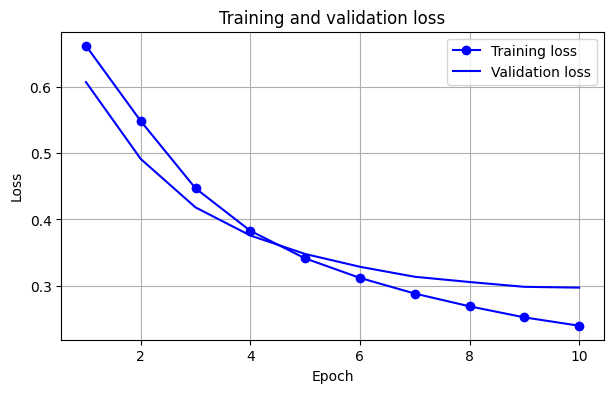

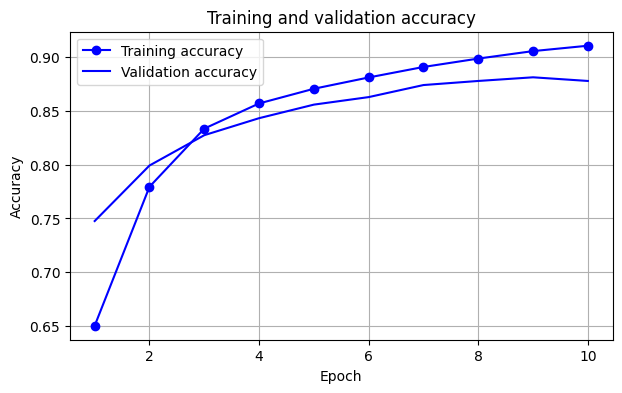

In [ ]:
history_dict = history.history
epochs_range = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history_dict["loss"], "bo-", label="Training loss")
plt.plot(epochs_range, history_dict["val_loss"], "b-", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history_dict["binary_accuracy"], "bo-", label="Training accuracy")
plt.plot(epochs_range, history_dict["val_binary_accuracy"], "b-", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
export_model = tf.keras.Sequential([
    vectorize_layer,
    model
])

export_model.compile(
    loss=losses.BinaryCrossentropy(from_logits=False),
    optimizer="adam",
    metrics=["accuracy"]
)

export_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 250)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (1, 1)                 │       160,017 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,017 (625.07 KB)

 Trainable params: 160,017 (625.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
test_metrics = export_model.evaluate(raw_test_ds, return_dict=True)
print("Test loss:", test_metrics["loss"])
print("Test accuracy:", test_metrics["accuracy"])

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8635 - loss: 0.3207
Test loss: 0.3206838071346283
Test accuracy: 0.8635200262069702


In [ ]:
new_reviews = tf.constant([
    "The movie was wonderful, beautifully acted, and I enjoyed every minute.",
    "This film was boring, poorly written, and a complete waste of time.",
    "The story was okay. Some scenes were good, but the ending was disappointing.",
    "A fantastic movie with excellent performances and an emotional story."
])

scores = export_model.predict(new_reviews, verbose=0)

for review, score_array in zip(new_reviews.numpy(), scores):
    score = float(score_array[0])
    sentiment = "Positive" if score >= 0.5 else "Negative"
    print("\\nReview:", review.decode("utf-8"))
    print(f"Positive sentiment score: {score:.4f}")
    print("Predicted sentiment:", sentiment)

\nReview: The movie was wonderful, beautifully acted, and I enjoyed every minute.
Positive sentiment score: 0.8988
Predicted sentiment: Positive
\nReview: This film was boring, poorly written, and a complete waste of time.
Positive sentiment score: 0.2148
Predicted sentiment: Negative
\nReview: The story was okay. Some scenes were good, but the ending was disappointing.
Positive sentiment score: 0.5797
Predicted sentiment: Positive
\nReview: A fantastic movie with excellent performances and an emotional story.
Positive sentiment score: 0.9284
Predicted sentiment: Positive


In [ ]:
export_model.save("imdb_sentiment_export.keras")
print("Saved as imdb_sentiment_export.keras")

Saved as imdb_sentiment_export.keras
